In [2]:
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tifffile import TiffFile
from sklearn.ensemble import IsolationForest
from framework.dataset import LandCoverData as LCD

In [3]:
# Images du jeu d'entraînement
DATASET_FOLDER = Path("local_dataset/")
train_images_paths = sorted(
    list(DATASET_FOLDER.glob('train/images/*.tif'))
)

In [4]:
def read_image(path) -> np.ndarray:
    """-> (H, W, 4) float32, normalized """
    with TiffFile(path) as t:
        img = t.asarray()
    if img.shape[-1] != LCD.N_CHANNELS and img.shape[0] == LCD.N_CHANNELS:
        img = np.transpose(img, (1, 2, 0)) 
    return img.astype(np.float32) / LCD.TRAIN_PIXELS_MAX

In [5]:
# =====================================================
# EXTRACTION DES CARACTÉRISTIQUES
# =====================================================

features = []

for file in train_images_paths:

    image =  read_image(file)

    # Les 4 bandes : Blue, Green, Red, NIR
    row = []

    # Statistiques des 4 bandes
    for i in range(4):

        band = image[..., i]
        values = band[np.isfinite(band)]

        row.extend([
            np.mean(values),
            np.std(values),
            np.percentile(values, 5),
            np.percentile(values, 50),
            np.percentile(values, 95)
        ])

    # NDVI : Red = bande 3, NIR = bande 4
    red = image[..., 2]
    nir = image[..., 3]

    denominator = nir + red
    valid = np.isfinite(denominator) & (denominator != 0)

    ndvi = (nir[valid] - red[valid]) / denominator[valid]

    row.extend([
        np.mean(ndvi),
        np.std(ndvi)
    ])

    features.append(row)

features = np.array(features)

In [13]:
# =====================================================
# DÉTECTION DES IMAGES ATYPIQUES
# =====================================================


X = features

model = IsolationForest(
    contamination=0.01,
    random_state=42
)

predictions = model.fit_predict(X)

# Score : plus il est faible, plus l'image est atypique
scores = model.decision_function(X)

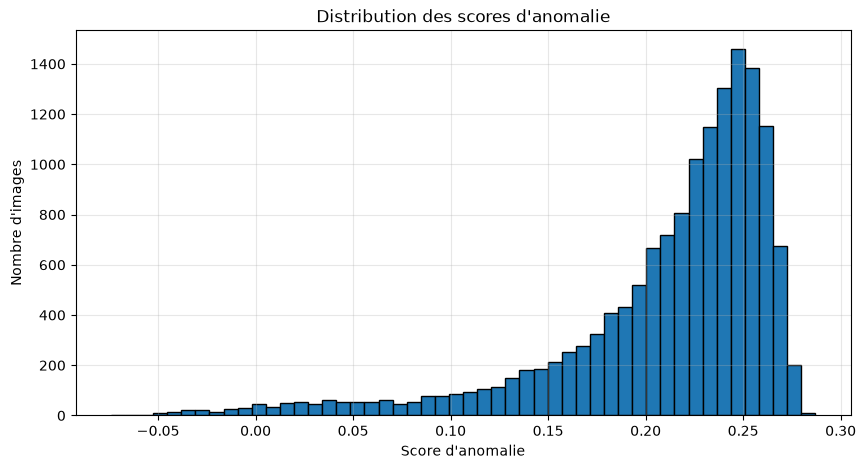

In [14]:
plt.figure(figsize=(10, 5))

plt.hist(scores, bins=50, edgecolor="black")

plt.xlabel("Score d'anomalie")
plt.ylabel("Nombre d'images")
plt.title("Distribution des scores d'anomalie")

plt.grid(alpha=0.3)
plt.show()

In [15]:
# =====================================================
# RÉSULTATS
# =====================================================

results = pd.DataFrame({
    "Image": [os.path.basename(f) for f in train_images_paths],
    "Outlier": predictions == -1,
    "Score": scores
})

results = results.sort_values("Score")

print(results)

           Image  Outlier     Score
9552    4148.tif     True -0.074239
4824   20014.tif     True -0.070731
4861   20059.tif     True -0.068702
14774   9978.tif     True -0.060932
4933   20138.tif     True -0.055383
...          ...      ...       ...
6039   21385.tif    False  0.280821
6384   21765.tif    False  0.282010
6080   21430.tif    False  0.282238
6456   21840.tif    False  0.283036
5246   20498.tif    False  0.287032

[14794 rows x 3 columns]


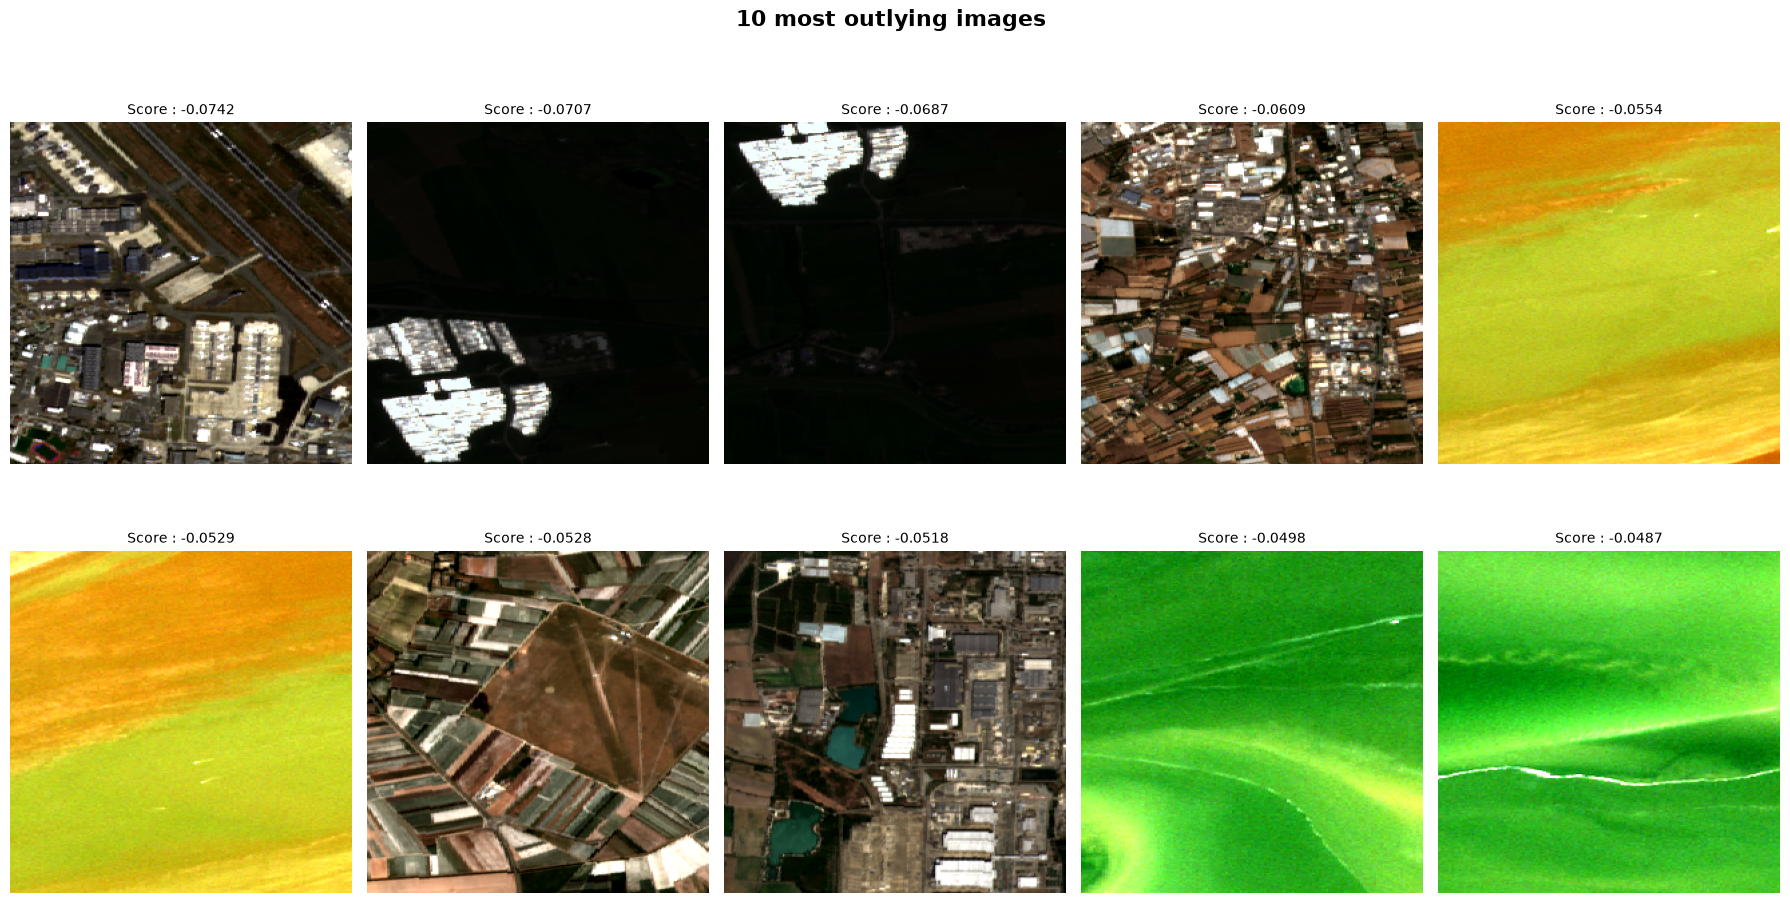

In [26]:
# =====================================================
# AFFICHAGE DES 5 IMAGES LES PLUS ATYPIQUES
# =====================================================
n_images = 10

outlier_indices = np.argsort(scores)[:n_images]

fig, axes = plt.subplots(
    2, 5,
    figsize=(18, 10),
    squeeze=False
)

for i, idx in enumerate(outlier_indices):

    row = i // 5
    col = i % 5

    image = read_image(train_images_paths[idx])
    rgb = image[..., [2, 1, 0]]

    p2 = np.percentile(rgb, 2)
    p98 = np.percentile(rgb, 98)

    rgb = np.clip(
        (rgb - p2) / (p98 - p2 + 1e-8),
        0, 1
    )

    axes[row, col].imshow(rgb)

    axes[row, col].set_title(
        f"Score : {scores[idx]:.4f}",
        fontsize=10
    )

    axes[row, col].axis("off")

plt.suptitle(
    "10 most outlying images ",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [9]:
# # =====================================================
# # RÉSULTATS
# # =====================================================

# print(results)

# # =====================================================
# # EXPORT DES IMAGES À IGNORER
# # =====================================================

# outliers = results[results["Outlier"] == True].copy()

# outliers["sample_id"] = (
#     outliers["Image"]
#     .str.extract(r'(\d+)')
#     .astype(int)
# )

# outliers[["sample_id"]].to_csv(
#     "local_dataset/ignored_labels.csv",
#     index=False
# )

# print(f"\n{len(outliers)} images à ignorer.")
# print("Fichier ignored_labels.csv created.")